# From H&E slide to survival curve — a walkthrough on fake data

Everything here runs on a laptop CPU in a few minutes, with **no real patient data**:

| Part | What you see | Repo file |
|---|---|---|
| 1 | A fake H&E slide: resolution, µm per pixel | — |
| 2 | Tiling it with `wsi_patching`: which tiles survive the filters | `patching/pipeline.py` |
| 3 | Turning tiles into vectors with a frozen encoder | `encoders/foundation.py` |
| 4 | A fake cohort: censoring, Kaplan–Meier | `scripts/make_synthetic_cohort.py`, `data/cohort.py` |
| 5 | A patient = a bag of tile vectors | `data/dataset.py` |
| 6 | **The Cox model by hand**: risk sets, partial likelihood, why the baseline cancels | `losses.py` |
| 7 | From a Cox score to a survival curve (Breslow) | `survival.py` |
| 8 | The discrete-time alternative (NLL loss) | `losses.py`, `survival.py` |
| 9 | Training attention MIL on one fold, written out | `models/mil.py`, `training/trainer.py` |
| 10 | Metrics: C-index by hand, td-AUC, Brier score vs Kaplan–Meier | `metrics.py` |
| 11 | Risk groups and what attention looked at | `evaluation.py` |
| 12 | The honest comparison: a mean-pool baseline, full cross-validation | `scripts/baseline_cox.py`, `scripts/train_survival.py` |

Run from the repo root or from `notebooks/` after `pip install -e ".[patching,dev]"`.
Part 3 downloads ImageNet ResNet-50 weights (~100 MB) once.

In [1]:
import subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
WORK = ROOT / "data" / "walkthrough"
WORK.mkdir(parents=True, exist_ok=True)

HEMA, EOSIN, GOLD, GREY = "#4a3fc2", "#c23a70", "#c8941e", "#8a8499"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
torch.manual_seed(0)
print("repo:", ROOT)

repo: /Users/matthiashagenauer/Documents/code_folder/thesis/wsi-survival-starter


## 1 · A whole-slide image

Real slides are 50k–150k pixels per side and stored as an **image pyramid** (full resolution + downsampled
copies). What matters is the physical pixel size, **µm per pixel (mpp)**:

| scanner "magnification" | mpp | a 224 px tile covers |
|---|---|---|
| 40× | ~0.25 | 56 µm |
| 20× | ~0.5 | 112 µm — what UNI2 / Virchow2 / H-optimus-1 were trained on |

We draw a small fake slide at 0.25 mpp: pink stroma (eosin), purple nuclei (hematoxylin), glands,
and one denser "tumour" region. It is saved as a tiled TIFF with resolution metadata, like a scanner would.

4096 x 3072 px at 0.25 µm/px  =  1.02 x 0.77 mm


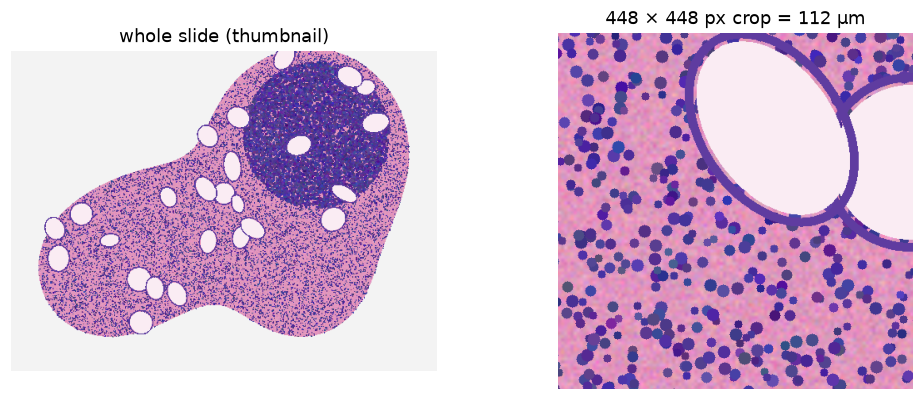

In [2]:
import cv2, tifffile

def fake_he_slide(path, h=3072, w=4096, mpp=0.25, seed=0):
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:h:4, 0:w:4]                      # tissue mask at low res, then upsample
    dens = np.zeros(yy.shape, np.float32)
    for _ in range(6):
        cy, cx, r = rng.uniform(.25, .75) * h, rng.uniform(.2, .8) * w, rng.uniform(.18, .3) * min(h, w)
        dens += np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / r ** 2)
    tissue = cv2.resize((dens > 0.55).astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)

    img = np.full((h, w, 3), 243, np.uint8)                                   # glass
    stroma = np.array([226, 150, 190]) + rng.normal(0, 12, (h // 4, w // 4, 3))
    stroma = cv2.resize(stroma.astype(np.float32), (w, h)).clip(0, 255).astype(np.uint8)
    img[tissue] = stroma[tissue]

    ty, tx = np.argwhere(tissue)[rng.integers(tissue.sum())]                  # tumour centre
    pts = np.argwhere(tissue)[rng.integers(0, tissue.sum(), 40000)]
    for y, x in pts:
        tumour = np.hypot(y - ty, x - tx) < 700
        if not tumour and rng.random() < 0.6:
            continue
        col = tuple(int(c) for c in (np.array([80, 55, 150]) + rng.normal(0, 15, 3)).clip(0, 255))
        cv2.circle(img, (int(x), int(y)), int(rng.integers(9, 15) if tumour else rng.integers(5, 9)), col, -1)
    for _ in range(25):                                                       # glands: lumen + ring of nuclei
        y, x = np.argwhere(tissue)[rng.integers(tissue.sum())]
        a, b, ang = int(rng.integers(60, 140)), int(rng.integers(50, 110)), float(rng.uniform(0, 180))
        cv2.ellipse(img, (int(x), int(y)), (a, b), ang, 0, 360, (250, 236, 243), -1)
        cv2.ellipse(img, (int(x), int(y)), (a + 10, b + 10), ang, 0, 360, (95, 60, 160), 9)
    tifffile.imwrite(path, img, photometric="rgb", tile=(256, 256), compression="deflate",
                     resolution=(1e4 / mpp, 1e4 / mpp), resolutionunit="CENTIMETER")
    return img

slide_path = WORK / "FAKE-001.tif"
img = fake_he_slide(slide_path)
print(f"{img.shape[1]} x {img.shape[0]} px at 0.25 µm/px  =  {img.shape[1]*0.25/1000:.2f} x {img.shape[0]*0.25/1000:.2f} mm")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].imshow(img[::8, ::8]); ax[0].set_title("whole slide (thumbnail)"); ax[0].axis("off")
ax[1].imshow(img[1200:1648, 1600:2048]); ax[1].set_title("448 × 448 px crop = 112 µm"); ax[1].axis("off")
plt.show()

## 2 · Tiling with `wsi_patching`

A pipeline is a chain of stages. It **streams**: tiles come out batch by batch, so a 3 GB slide is never
fully in memory.

```
WSIGrid(resolution=0.5, unit="mpp", fallback_mode="resample")   which slides, at exactly 0.5 µm/px
  → PatchExtractor(tile_size=224)                                 plan grid, read, cut
  → LowContrastBackgroundFilter                                   drop near-uniform tiles (glass)
  → RemoveEdgeTiles(depth=1)                                      drop the outer ring of tiles
  → TorchStreamWriter                                             yields (slide, tiles, coords, metadata)
```

`fallback_mode="resample"` matters: our slide only exists at 0.25 mpp, so the library reads it there and
resizes by ½. A 20× and a 40× scanner then give tiles of the same physical size.

Why the edge ring? The grid runs past the slide border and those tiles are **padded with black**. Black next
to white glass has high contrast, so the background filter keeps them. Dropping the outermost ring of
tiles removes them, together with ragged tissue edges.

First a **dry run**: run the filters, write nothing, and report what each stage dropped.

In [3]:
from wsisurv.patching.pipeline import build_pipeline

tile_cfg = {"target_mpp": 0.5, "tile_size": 224, "use_gpu": False,
            "filters": {"low_contrast_range": 0.2, "remove_edge_depth": 1}}

p = build_pipeline([str(slide_path)], tile_cfg)
p.dry_run(num_workers=1)
p.print_audit()


=== Audit: FAKE-001 ===
Stage                                  In        Out    Dropped   Drop %
PatchExtractor                         70         70          0     0.0%
LowContrastBackgroundFilter            70         61          9    12.9%
RemoveEdgeTiles                        61         37         24    39.3%


Now stream the real tiles. Each batch: `tiles` float 0–255 `(N, 3, 224, 224)`, `coords` = top-left corner
`(x, y)` **in the 0.5 mpp grid**.

> On real data: `make inspect SLIDE=...` writes the same audit as an interactive HTML overlay with sliders.

tiles: (37, 3, 224, 224) coords: (37, 2)  (full grid: 70 tiles)


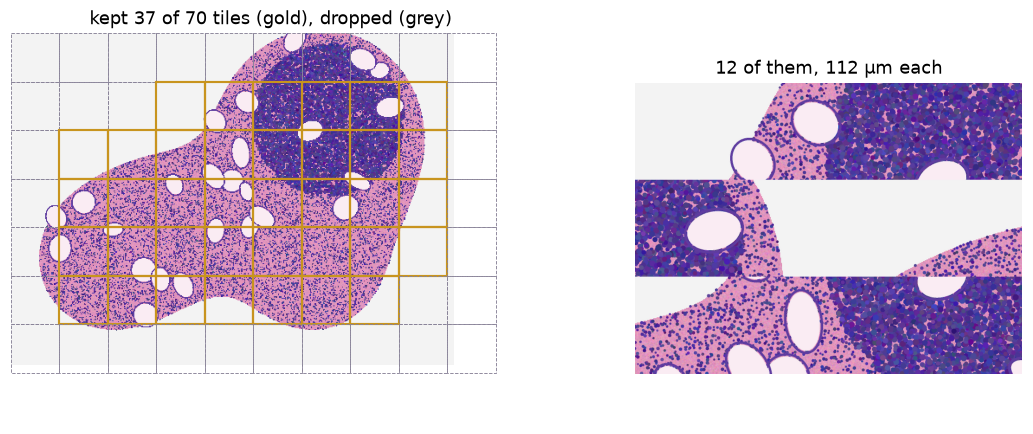

In [4]:
def stream(cfg):
    out = [(t, c) for _, t, c, _ in build_pipeline([str(slide_path)], cfg).stream(num_workers=1)]
    return torch.cat([o[0] for o in out]), torch.cat([o[1] for o in out])

tiles, coords = stream(tile_cfg)
_, all_coords = stream({**tile_cfg, "filters": {"low_contrast_range": None}})   # no filters: the full grid
print("tiles:", tuple(tiles.shape), "coords:", tuple(coords.shape), " (full grid:", len(all_coords), "tiles)")

thumb = img[::8, ::8]                     # 0.25 mpp / 8 = 2 µm per thumbnail pixel
f = 0.5 / 2.0                             # 0.5-mpp grid units -> thumbnail pixels
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
ax[0].imshow(thumb); ax[0].set_title(f"kept {len(tiles)} of {len(all_coords)} tiles (gold), dropped (grey)")
ax[0].set(xlim=(0, 600), ylim=(450, 0)); ax[0].axis("off")
kept = {tuple(c) for c in coords.tolist()}
for x, y in all_coords.tolist():
    k = (x, y) in kept
    ax[0].add_patch(plt.Rectangle((x * f, y * f), 224 * f, 224 * f, fill=False, ec=GOLD if k else GREY,
                                  lw=1.4 if k else 0.6, ls="-" if k else "--"))
grid = torch.cat([torch.cat(list(tiles[i * 4:(i + 1) * 4]), dim=2) for i in range(3)], dim=1)
ax[1].imshow(grid.permute(1, 2, 0).numpy().astype(np.uint8)); ax[1].axis("off"); ax[1].set_title("12 of them, 112 µm each")
plt.show()

## 3 · From tile to vector: a frozen encoder

Each tile goes through a pretrained vision transformer **once** and becomes a vector. We never train the
encoder; that is what makes a few hundred patients enough.

On real data you use a pathology foundation model (UNI2-h, 1536-d). Those weights need a Hugging Face
login, so here we use an open **ImageNet ResNet-50** (2048-d) — same code path, worse features.

Note the normalisation inside `FoundationEncoder.forward`: tiles arrive as 0–255 and every model expects
`x/255` then its own mean/std. Forgetting this does not crash; it silently gives bad vectors.

/private/tmp/claude-501/-Users-matthiashagenauer-Documents-code-folder-thesis/ef0653de-87ad-43aa-8546-6757cbd1efdf/scratchpad/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[2026-11-19 11:11:48,964] [WARNING] [MainProcess] [huggingface_hub.utils._http] Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


embeddings: (37, 2048)   (one row per tile)


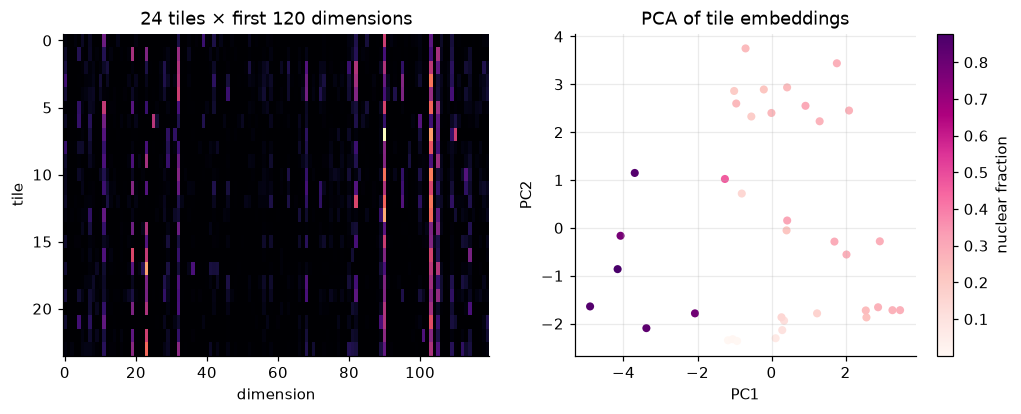

In [5]:
from wsisurv.encoders.foundation import FoundationEncoder

encoder = FoundationEncoder("resnet50").eval()   # real data: FoundationEncoder("UNI2")
with torch.inference_mode():
    emb = torch.cat([encoder(tiles[i:i + 32]) for i in range(0, len(tiles), 32)])
print("embeddings:", tuple(emb.shape), "  (one row per tile)")

# Does the vector know anything about the tissue? Colour tiles by how much of them is nuclei.
nuclear = ((tiles[:, 2] > tiles[:, 0]) & (tiles.mean(1) < 150)).float().mean((1, 2))  # bluish & dark pixels
from sklearn.decomposition import PCA
pc = PCA(2).fit_transform(emb.numpy())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].imshow(emb[:24, :120].numpy(), aspect="auto", cmap="magma"); ax[0].set(title="24 tiles × first 120 dimensions", xlabel="dimension", ylabel="tile"); ax[0].grid(False)
s = ax[1].scatter(pc[:, 0], pc[:, 1], c=nuclear, cmap="RdPu", s=28, ec="none")
ax[1].set(title="PCA of tile embeddings", xlabel="PC1", ylabel="PC2"); plt.colorbar(s, ax=ax[1], label="nuclear fraction")
plt.show()

Even ImageNet features sort tiles by how cellular they are. Pathology encoders separate much finer
morphology (growth patterns, immune cells, necrosis).

On real data this is `scripts/embed_slides.py`: it does Parts 2–3 for every slide in the cohort table and
saves `embeddings/<slide_id>.pt` = `{embeddings, coords, slide_id, encoder, mpp, tile_size}`.

## 4 · A fake cohort, and what censoring means

Embedding real slides takes GPU-days, so from here on we use **simulated embeddings** with a known answer
(`scripts/make_synthetic_cohort.py`):

- each patient has a hidden fraction *f* of "aggressive" tiles; those tiles are shifted along one secret direction in a 64-d space
- hazard = 0.02 · exp(6 · *f* + 0.03 · (age − 65)) → exponential survival times
- random drop-out, and the study ends at 100 months → **censoring**

Because we know *f*, we know the best possible C-index (the "oracle").

In [6]:
syn = WORK / "synthetic"
print(subprocess.run([sys.executable, ROOT / "scripts/make_synthetic_cohort.py", "--out", syn],
                     capture_output=True, text=True, check=True).stdout)
slides = pd.read_csv(syn / "cohort.csv")
slides.head(6)

oracle C-index (true risk) = 0.712
300 patients, 456 slides, 83% events -> /Users/matthiashagenauer/Documents/code_folder/thesis/wsi-survival-starter/data/walkthrough/synthetic



,patient_id,slide_id,wsi_path,time,event,age,true_aggressive_fraction
0,P0000,P0000_A,P0000_A.svs,11.62,0,78.2,0.0850
1,P0000,P0000_B,P0000_B.svs,11.62,0,78.2,0.0850
2,P0001,P0001_A,P0001_A.svs,4.52,0,53.1,0.1772
3,P0001,P0001_B,P0001_B.svs,4.52,0,53.1,0.1772
4,P0002,P0002_A,P0002_A.svs,49.84,0,69.4,0.0880
5,P0002,P0002_B,P0002_B.svs,49.84,0,69.4,0.0880


The table is **one row per slide**; `time` / `event` are per patient (event = 1: died, 0: censored).
Censored patients are *not* survivors — we only know they lived **at least** that long.

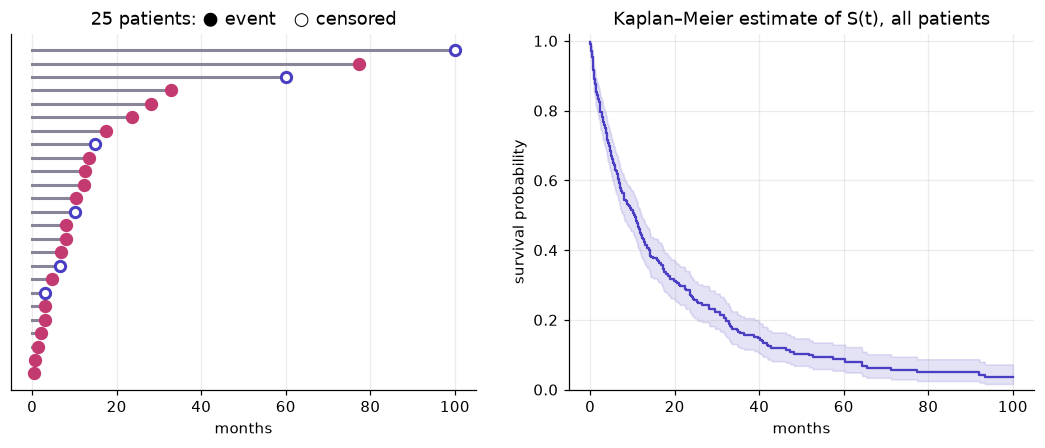

300 patients, 83% events, median follow-up 7.9 months


In [7]:
from wsisurv.data.cohort import load_slide_table, patient_table, keep_embedded

patients = keep_embedded(patient_table(load_slide_table(syn / "cohort.csv")), syn / "embeddings")

show = patients.sample(25, random_state=1).sort_values("time")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for i, (pid, r) in enumerate(show.iterrows()):
    ax[0].plot([0, r.time], [i, i], color=GREY, lw=2)
    ax[0].scatter(r.time, i, s=45, zorder=3, color=EOSIN if r.event else "white", ec=EOSIN if r.event else HEMA, lw=2)
ax[0].set(title="25 patients: ● event   ○ censored", xlabel="months", yticks=[])

from sksurv.nonparametric import kaplan_meier_estimator
t, s, (lo, hi) = kaplan_meier_estimator(patients.event.astype(bool), patients.time, conf_type="log-log")
ax[1].step(t, s, where="post", color=HEMA); ax[1].fill_between(t, lo, hi, step="post", color=HEMA, alpha=0.15)
ax[1].set(title="Kaplan–Meier estimate of S(t), all patients", xlabel="months", ylabel="survival probability", ylim=(0, 1.02))
plt.show()
print(f"{len(patients)} patients, {patients.event.mean():.0%} events, median follow-up {patients.time.median():.1f} months")

## 5 · A patient is a bag of tiles

All tiles of all slides of a patient are concatenated into one **bag**. The label belongs to the bag, not to
any tile — this is *multiple instance learning* (think: a sample of thousands of cells with one phenotype).

P0096: bag (409, 64), slides ['P0096_A', 'P0096_B'], time 3.2, event 1, aggressive tiles 0%
P0160: bag (727, 64), slides ['P0160_A', 'P0160_B'], time 4.3, event 1, aggressive tiles 69%


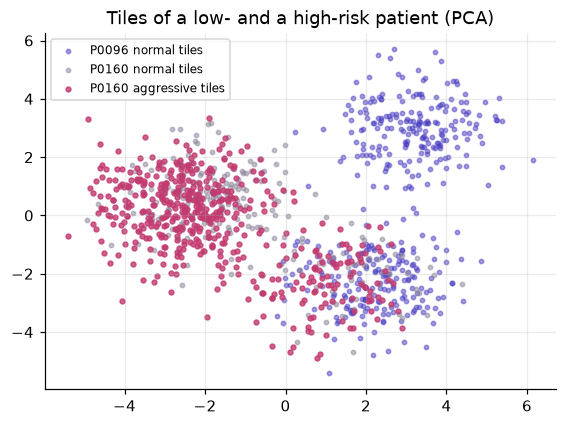

In [8]:
from wsisurv.data.dataset import PatientBagDataset

ds = PatientBagDataset(patients, syn / "embeddings")
hi_pid = patients.true_aggressive_fraction.idxmax(); lo_pid = patients.true_aggressive_fraction.idxmin()

def tile_truth(pid):   # fake data only: which tiles were made "aggressive"
    return torch.cat([torch.load(syn / "embeddings" / f"{s}.pt", weights_only=False)["tile_is_aggressive"]
                      for s in patients.at[pid, "slide_ids"]])

bags = {pid: ds[ds.ids.index(pid)] for pid in (lo_pid, hi_pid)}
for pid, b in bags.items():
    print(f"{pid}: bag {tuple(b['features'].shape)}, slides {patients.at[pid, 'slide_ids']}, "
          f"time {b['time']:.1f}, event {int(b['event'])}, aggressive tiles {tile_truth(pid).float().mean():.0%}")

both = torch.cat([b["features"] for b in bags.values()]).numpy()
pc = PCA(2).fit(both)
fig, ax = plt.subplots(figsize=(6, 4.2))
for pid, b in bags.items():
    z, agg = pc.transform(b["features"].numpy()), tile_truth(pid).numpy()
    ax.scatter(z[~agg, 0], z[~agg, 1], s=8, alpha=.5, color=HEMA if pid == lo_pid else GREY, label=f"{pid} normal tiles")
    ax.scatter(z[agg, 0], z[agg, 1], s=10, alpha=.8, color=EOSIN, label=f"{pid} aggressive tiles" if pid == hi_pid else None)
ax.legend(fontsize=8); ax.set(title="Tiles of a low- and a high-risk patient (PCA)"); plt.show()

The model has to discover, without tile labels, that the pink cloud is what predicts short survival.

Also visible: the low-risk patient's tiles form **two** clouds, one per slide. Each fake slide has its own
constant offset, standing in for stain and scanner differences. Real slides have them too, and a model can
learn them instead of biology, which is why splits by site and per-site metrics matter.

## 6 · The Cox model, by hand

**The model.** Every patient has a hazard (event rate right now, given still event-free):

$$h(t\mid x) = h_0(t)\,\cdot\,e^{\,r(x)}$$

- $h_0(t)$: baseline hazard, the same shape over time for everyone, never specified
- $r(x)$: the patient's **risk score**. Classic Cox: $r = \beta^\top x$. Here: $r$ = MIL network(bag).
- $e^{r}$ is the **hazard ratio**: $r = 0.69$ means twice the hazard, at every time point (*proportional hazards*).

**The training signal.** At each event time, ask: *of everyone still at risk, what probability did the model
give to the one who actually had the event?*

$$p_i = \frac{h_0(t_i)\,e^{r_i}}{\sum_{j:\,t_j \ge t_i} h_0(t_i)\,e^{r_j}} = \frac{e^{r_i}}{\sum_{j:\,t_j \ge t_i} e^{r_j}},
\qquad \text{loss} = -\frac{1}{N_\text{events}}\sum_{i:\,\delta_i=1}\log p_i$$

$h_0$ cancels. Let's do it with six patients.

In [9]:
toy = pd.DataFrame({"time":  [6, 10, 15, 22, 28, 34],
                    "event": [1,  0,  1,  1,  0,  1],
                    "r":     [1.0, 0.3, 0.6, -0.4, 0.2, 0.0]}, index=list("ABCDEF"))

rows, exact = [], []
for pid, e in toy[toy.event == 1].iterrows():
    risk_set = toy[toy.time >= e.time]                       # still event-free just before t_i
    p = np.exp(e.r) / np.exp(risk_set.r).sum()
    exact.append(-np.log(p))
    rows.append({"event": f"{pid} @ {e.time:g} mo", "risk set": ", ".join(risk_set.index),
                 "p (model's share for the one it happened to)": round(p, 3), "-log p": abs(round(-np.log(p), 3))})
terms = pd.DataFrame(rows)
display(terms)
print("Cox loss by hand :", round(float(np.mean(exact)), 4))

from wsisurv.losses import cox_ph_loss
T = lambda col: torch.tensor(toy[col].values, dtype=torch.float32)
print("cox_ph_loss()    :", round(cox_ph_loss(T("r"), T("time"), T("event")).item(), 4))

,event,risk set,p (model's share for the one it happened to),-log p
0,A @ 6 mo,"A, B, C, D, E, F",0.310,1.173
1,C @ 15 mo,"C, D, E, F",0.387,0.951
2,D @ 22 mo,"D, E, F",0.232,1.462
3,F @ 34 mo,F,1.000,0.000


Cox loss by hand : 0.8963
cox_ph_loss()    : 0.8963


Things to notice in that table:

- **Censored patients (B, E)** never get a term of their own, but they sit in every risk set until they leave. That is how censoring is used rather than thrown away.
- **The last event (F)** is alone in its risk set: $p = 1$, $-\log p = 0$. It teaches nothing.
- Only the **order** of event times matters, not their values.

Three consequences you can check numerically:

1) shift all scores by +5         : 0.8963  <- unchanged: only RELATIVE risk is learned
2) stretch times (t -> t^2 * 3)   : 0.8963  <- unchanged: only the ORDER of times matters
3) batch of ONE patient           : 0.0     <- risk set = {itself}: p = 1, zero gradient


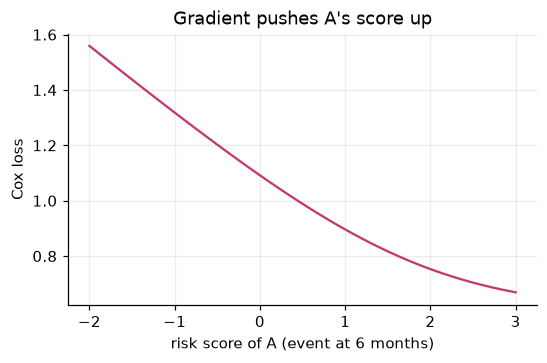

In [10]:
r, t, e = T("r"), T("time"), T("event")
print("1) shift all scores by +5         :", round(cox_ph_loss(r + 5, t, e).item(), 4), " <- unchanged: only RELATIVE risk is learned")
print("2) stretch times (t -> t^2 * 3)   :", round(cox_ph_loss(r, t ** 2 * 3, e).item(), 4), " <- unchanged: only the ORDER of times matters")
print("3) batch of ONE patient           :", abs(cox_ph_loss(r[:1], t[:1], e[:1]).item()), "    <- risk set = {itself}: p = 1, zero gradient")

# The loss as a function of A's score: raising the risk of someone who died early is rewarded
grid = np.linspace(-2, 3, 60)
losses = [cox_ph_loss(torch.tensor([g, *toy.r.values[1:]], dtype=torch.float32), t, e).item() for g in grid]
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(grid, losses, color=EOSIN); ax.set(xlabel="risk score of A (event at 6 months)", ylabel="Cox loss", title="Gradient pushes A's score up")
plt.show()

**Consequence 3 is the important one for MIL.** Each bag is thousands of tiles, which tempts you into
batch size 1 — and then the Cox loss gives no signal. The template samples a fixed number of tiles per
patient during training (`n_tiles`) so that 32 patients fit in a batch, and uses all tiles at test time.

## 7 · From a Cox score to a survival curve

Because $h_0$ cancelled, a Cox network only gives a **ranking**. To say "60 % alive at 3 years" we estimate
the baseline afterwards with **Breslow's estimator**, then every patient's curve is

$$S(t\mid x) = S_0(t)^{\,e^{r}}$$

one shared shape, bent down for high $r$ and up for low $r$. The Brier score in Part 10 needs these curves.

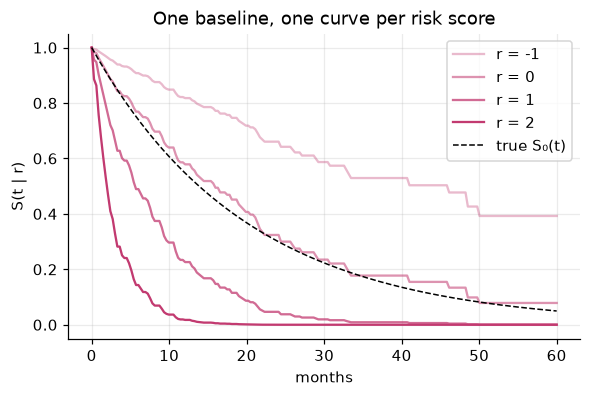

In [11]:
from wsisurv.survival import breslow_baseline, cox_curve_at

rng = np.random.default_rng(0)                       # 200 patients from a known Cox model, true r ~ N(0,1)
r_true = rng.normal(size=200)
t_ev = rng.exponential(20 / np.exp(r_true)); t_c = rng.uniform(0, 60, 200)
tt, ee = np.minimum(t_ev, t_c), (t_ev <= t_c).astype(int)

baseline = breslow_baseline(r_true, tt, ee)
grid_t = np.linspace(0, 60, 200)
fig, ax = plt.subplots(figsize=(6, 3.6))
for rv, a in zip([-1, 0, 1, 2], [.35, .55, .75, 1]):
    ax.plot(grid_t, cox_curve_at(np.array([rv]), baseline, grid_t)[0], color=EOSIN, alpha=a, label=f"r = {rv}")
ax.plot(grid_t, np.exp(-grid_t / 20), "k--", lw=1, label="true S₀(t)")
ax.set(xlabel="months", ylabel="S(t | r)", title="One baseline, one curve per risk score"); ax.legend(); plt.show()

## 8 · The alternative: discrete-time NLL loss

Cut follow-up into $K$ bins (quantiles of the training event times). The model outputs one **hazard per
bin**, $h_k = P(\text{event in bin } k \mid \text{survived to } k)$, and $S(k) = \prod_{j\le k}(1-h_j)$.

- event in bin $y$: likelihood $S(y-1)\cdot h_y$ — survived the earlier bins, then had the event
- censored in bin $y$: likelihood $S(y)$ — survived at least through bin $y$

Each patient's loss stands alone → **works with batch size 1**, gives survival curves directly, and does
not assume proportional hazards. Most recent pathology papers use it (`loss: nll`, the template default).

In [12]:
from wsisurv.data.dataset import make_bin_edges, discretize_times
from wsisurv.losses import nll_discrete_loss
from wsisurv.survival import discrete_survival, discrete_risk

edges = make_bin_edges(patients.time.values, patients.event.values, n_bins=4)
print("bin edges (months):", edges.round(1))

logits = torch.tensor([[-2.0, -1.5, -1.0, -0.5],     # patient 1: low hazards
                       [-0.5,  0.0,  0.5,  1.0]])    # patient 2: high hazards
surv = discrete_survival(logits)
print("hazard per bin:\n", torch.sigmoid(logits).numpy().round(2))
print("S at end of each bin:\n", surv.numpy().round(2))
print("risk score (-sum S):", discrete_risk(logits).numpy().round(2), " <- higher = worse, used for the C-index")

# patient 1 censored in bin 2, patient 2 died in bin 1
bins, event = torch.tensor([2, 1]), torch.tensor([0.0, 1.0])
by_hand = -(torch.log(surv[0, 2]) + torch.log(surv[1, 0] * torch.sigmoid(logits[1, 1]))) / 2
print("NLL loss:", round(nll_discrete_loss(logits, bins, event).item(), 4), " by hand:", round(by_hand.item(), 4))

bin edges (months): [ 2.8  7.6 18.4]
hazard per bin:
 [[0.12 0.18 0.27 0.38]
 [0.38 0.5  0.62 0.73]]
S at end of each bin:
 [[0.88 0.72 0.53 0.33]
 [0.62 0.31 0.12 0.03]]
risk score (-sum S): [-2.46 -1.08]  <- higher = worse, used for the C-index
NLL loss: 0.9044  by hand: 0.9044


## 9 · Training attention MIL on one fold — written out

`scripts/train_survival.py` does all of this for 5 folds. Here is one fold, by hand, so nothing is hidden.

**Attention MIL (ABMIL)**: each tile vector gets a learned weight $a_i$ (softmax over the bag); the patient
vector is $\sum_i a_i h_i$; a linear layer turns it into one Cox risk score.

train 240 patients (200 events) | test 60 patients (49 events)


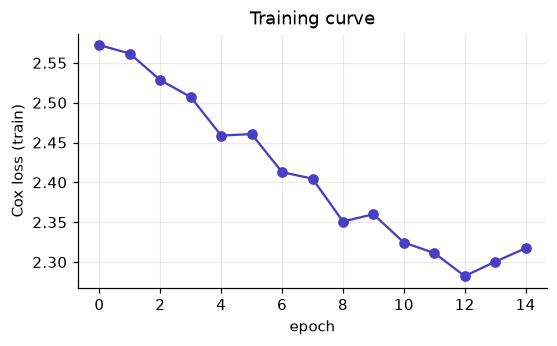

In [13]:
from torch.utils.data import DataLoader
from wsisurv.data.splits import patient_folds
from wsisurv.models.mil import ABMIL
from wsisurv.training.trainer import predict

folds = patient_folds(patients, n_folds=5, seed=0)           # split by PATIENT, stratified by event
fold = folds[0]
tr, te = patients.loc[fold.train], patients.loc[fold.test]
print(f"train {len(tr)} patients ({tr.event.sum()} events) | test {len(te)} patients ({te.event.sum()} events)")

train_ds = PatientBagDataset(tr, syn / "embeddings", n_tiles=256, seed=0)   # 256 random tiles per bag -> batchable
loader = DataLoader(train_ds, batch_size=32, shuffle=True, drop_last=True)

torch.manual_seed(0)
model = ABMIL(input_dim=64, n_outputs=1, hidden_dim=128, dropout=0.25)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

history = []
for epoch in range(15):
    model.train(); losses = []
    for batch in loader:
        risk = model(batch["features"]).squeeze(-1)                      # (32,) one score per patient
        loss = cox_ph_loss(risk, batch["time"], batch["event"])          # risk sets = this batch
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    history.append(np.mean(losses))

fig, ax = plt.subplots(figsize=(5.5, 3)); ax.plot(history, marker="o", color=HEMA)
ax.set(xlabel="epoch", ylabel="Cox loss (train)", title="Training curve"); plt.show()

At test time every tile is used (no sampling), one patient at a time. No epoch was chosen by looking at
the test fold — with a fixed schedule there is nothing to tune on it. (To select epochs, set `val_fraction`.)

In [14]:
eval_tr = PatientBagDataset(tr, syn / "embeddings", cache=False)
eval_te = PatientBagDataset(te, syn / "embeddings", cache=False)
risk_tr = predict(model, eval_tr, "cpu")[:, 0]
risk_te = predict(model, eval_te, "cpu")[:, 0]
pd.DataFrame({"time": te.time, "event": te.event, "predicted risk": risk_te.round(2),
              "true aggressive fraction": te.true_aggressive_fraction}).head(8)

,time,event,predicted risk,true aggressive fraction
patient_id,,,,
P0002,49.84,0,-0.76,0.0880
P0012,3.16,0,-0.76,0.0063
P0014,1.80,1,-0.05,0.1505
P0016,31.55,1,0.24,0.1627
P0021,8.84,1,-0.73,0.0565
P0023,3.73,1,1.34,0.5605
P0034,17.13,1,0.09,0.1609
P0042,27.59,0,-0.38,0.1277


## 10 · Did it work? Metrics

**Harrell's C-index**: over all *comparable* pairs (the patient with the shorter time had an event), the
fraction where that patient got the higher risk. 0.5 = coin flip, 1 = perfect. Let's compute it with a loop.

In [15]:
from sksurv.metrics import concordance_index_censored

def harrell_c(time, event, risk):
    conc = comp = 0
    for i in range(len(time)):
        for j in range(len(time)):
            if time[i] < time[j] and event[i] == 1:          # i failed first -> comparable
                comp += 1
                conc += 1.0 if risk[i] > risk[j] else 0.5 if risk[i] == risk[j] else 0.0
    return conc / comp, comp

c, n_pairs = harrell_c(te.time.values, te.event.values, risk_te)
print(f"C-index by hand: {c:.3f}  ({n_pairs} comparable pairs)")
print(f"scikit-survival: {concordance_index_censored(te.event.astype(bool), te.time, risk_te)[0]:.3f}")
print(f"oracle (true f): {concordance_index_censored(te.event.astype(bool), te.time, te.true_aggressive_fraction)[0]:.3f}  <- the ceiling")

C-index by hand: 0.656  (1553 comparable pairs)
scikit-survival: 0.656
oracle (true f): 0.755  <- the ceiling


The C-index only checks **ranking**. Two more views:

- **time-dependent AUC**: at month *t*, does the score separate "event by *t*" from "still event-free at *t*"?
- **Brier score**: squared error between predicted $S(t)$ and what happened, inverse-probability-of-censoring
  weighted. Lower is better, and it is only meaningful **next to the Kaplan–Meier reference** (everyone gets
  the population curve). The *integrated* Brier score (IBS) averages it over time.

Every IPCW metric estimates the censoring distribution from the **training** fold.

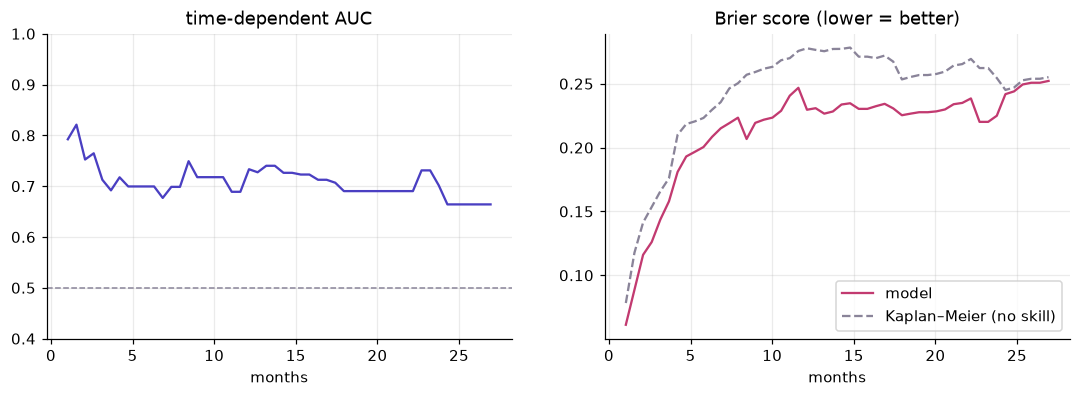

n                   60.000
events              49.000
c_index              0.656
c_index_uno          0.651
mean_td_auc          0.734
ibs                  0.215
ibs_km_reference     0.245
dtype: float64

In [16]:
from sksurv.metrics import brier_score, cumulative_dynamic_auc
from wsisurv.metrics import as_surv, eval_times, km_reference_curve, survival_metrics

y_tr, y_te = as_surv(tr.time, tr.event), as_surv(te.time, te.event)
times = eval_times(tr.time.values, tr.event.values, te.time.values, te.event.values)

surv_te = cox_curve_at(risk_te, breslow_baseline(risk_tr, tr.time.values, tr.event.values), times)
km = np.tile(km_reference_curve(tr.time.values, tr.event.values, times), (len(te), 1))

auc, _ = cumulative_dynamic_auc(y_tr, y_te, risk_te, times)
_, bs_model = brier_score(y_tr, y_te, surv_te, times)
_, bs_km = brier_score(y_tr, y_te, km, times)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(times, auc, color=HEMA); ax[0].axhline(0.5, color=GREY, ls="--", lw=1)
ax[0].set(title="time-dependent AUC", xlabel="months", ylim=(0.4, 1))
ax[1].plot(times, bs_model, color=EOSIN, label="model"); ax[1].plot(times, bs_km, color=GREY, ls="--", label="Kaplan–Meier (no skill)")
ax[1].set(title="Brier score (lower = better)", xlabel="months"); ax[1].legend(); plt.show()

pd.Series(survival_metrics(tr.time, tr.event, te.time, te.event, risk_te, surv_at_times=surv_te, times=times)).round(3)

## 11 · Risk groups, and what the attention looked at

The classic figure: split test patients at the **training** median risk (a test median would leak), plot
Kaplan–Meier per group, and test with log-rank. A tiny p-value is easy to get; it says the groups differ,
not that the model is good.

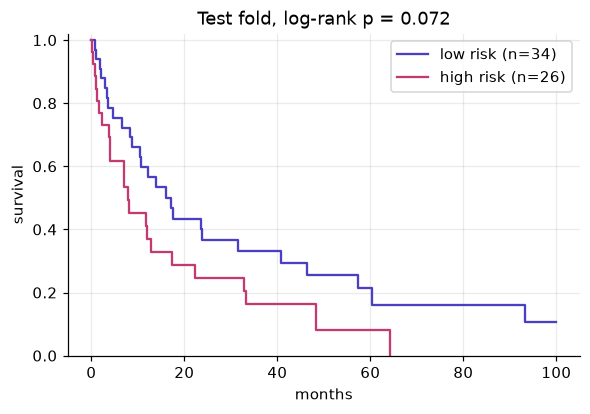

In [17]:
from sksurv.compare import compare_survival

high = risk_te > np.median(risk_tr)
fig, ax = plt.subplots(figsize=(6, 3.8))
for g, name, col in [(False, "low risk", HEMA), (True, "high risk", EOSIN)]:
    t_, s_ = kaplan_meier_estimator(te.event[high == g].astype(bool), te.time[high == g])
    ax.step(np.r_[0, t_], np.r_[1, s_], where="post", color=col, label=f"{name} (n={(high == g).sum()})")
_, pval = compare_survival(y_te, high.astype(int))
ax.set(title=f"Test fold, log-rank p = {pval:.2g}", xlabel="months", ylabel="survival", ylim=(0, 1.02)); ax.legend(); plt.show()

On fake data we know which tiles were "aggressive", so we can check whether attention found them. (On real
data you only get the heatmap — and attention shows how tiles were *weighted*, not what the prediction
*depends on*. Treat it as a hint, not an explanation.)

aggressive tiles receive on average 1.8x the attention of normal tiles (median over test patients)


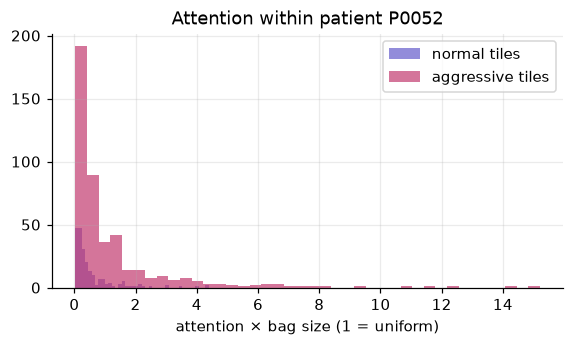

In [18]:
model.eval()
ratios = []
for i, pid in enumerate(eval_te.ids):
    with torch.no_grad():
        _, a = model(eval_te[i]["features"].unsqueeze(0), return_attention=True)
    a, agg = a[0].numpy(), tile_truth(pid).numpy()
    if 0 < agg.sum() < len(agg):
        ratios.append(a[agg].mean() / a[~agg].mean())
print(f"aggressive tiles receive on average {np.median(ratios):.1f}x the attention of normal tiles (median over test patients)")

pid = te.true_aggressive_fraction.idxmax(); i = eval_te.ids.index(pid)
with torch.no_grad():
    _, a = model(eval_te[i]["features"].unsqueeze(0), return_attention=True)
a, agg = a[0].numpy(), tile_truth(pid).numpy()
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(a[~agg] * len(a), bins=40, alpha=.6, color=HEMA, label="normal tiles")
ax.hist(a[agg] * len(a), bins=40, alpha=.7, color=EOSIN, label="aggressive tiles")
ax.set(xlabel="attention × bag size (1 = uniform)", title=f"Attention within patient {pid}"); ax.legend(); plt.show()

## 12 · The honest comparison

Before believing MIL, beat simple baselines **on the same folds**. The simplest: average all tile vectors
per patient, reduce with PCA, fit a (ridge) Cox model. Then run full 5-fold cross-validation and report
**mean ± std over folds**.

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sksurv.linear_model import CoxPHSurvivalAnalysis

mean_bag = lambda df: np.stack([ds[ds.ids.index(p)]["features"].mean(0).numpy() for p in df.index])
cox = make_pipeline(StandardScaler(), PCA(32, random_state=0), CoxPHSurvivalAnalysis(alpha=1.0))
cox.fit(mean_bag(tr), y_tr)
c_base = concordance_index_censored(te.event.astype(bool), te.time, cox.predict(mean_bag(te)))[0]
c_mil = concordance_index_censored(te.event.astype(bool), te.time, risk_te)[0]
print(f"fold 0  |  mean-pool + Cox: C = {c_base:.3f}   |   ABMIL + Cox: C = {c_mil:.3f}")

fold 0  |  mean-pool + Cox: C = 0.680   |   ABMIL + Cox: C = 0.656


In [20]:
# All 5 folds, both models, via the scripts (about a minute on CPU)
common = ["--set", f"cohort_table={syn}/cohort.csv", f"embedding_dir={syn}/embeddings", f"output_dir={WORK}/runs"]
subprocess.run([sys.executable, ROOT / "scripts/baseline_cox.py", "--config", ROOT / "configs/baseline_cox.yaml", *common],
               check=True, capture_output=True)
subprocess.run([sys.executable, ROOT / "scripts/train_survival.py", "--config", ROOT / "configs/synthetic.yaml",
                *common, "loss=cox", "batch_size=32", "run_name=abmil_cox"], check=True, capture_output=True)

summary = pd.DataFrame({name: pd.read_csv(WORK / "runs" / path / "summary.csv", index_col=0)["mean"]
                        for name, path in [("mean-pool + Cox", "baselines/mean_pool"), ("ABMIL + Cox", "abmil_cox")]}).T
fold_c = {name: pd.read_csv(WORK / "runs" / path / "fold_metrics.csv")["c_index"]
          for name, path in [("mean-pool + Cox", "baselines/mean_pool"), ("ABMIL + Cox", "abmil_cox")]}
summary.insert(0, "C-index (± std)", [f"{v.mean():.3f} ± {v.std():.3f}" for v in fold_c.values()])
summary.round(3)

,C-index (± std),c_index,c_index_uno,mean_td_auc,ibs,ibs_km_reference
mean-pool + Cox,0.613 ± 0.051,0.613,0.608,0.674,0.220,0.224
ABMIL + Cox,0.614 ± 0.034,0.614,0.607,0.662,0.221,0.224


Typically the two are within noise of each other — on this fake data and often on real data. That is the
point of the baseline.

## Checklist before trusting a result

- [ ] Folds split by **patient**, stratified by event (and site if pooled)
- [ ] Bins, PCA, scaling, Breslow baseline, risk-group cut-off fitted on **training** data only
- [ ] No epoch / hyperparameter chosen on the test fold
- [ ] C-index reported **per fold**, mean ± std (not pooled over folds)
- [ ] Brier score shown next to its **Kaplan–Meier** reference
- [ ] Beats clinical-only and mean-pool baselines on the **same** folds
- [ ] Per-site C-index checked (models love to learn the hospital)
- [ ] Endpoint chosen on purpose (OS vs DSS vs PFI; for TCGA use TCGA-CDR)

**Next step with real slides:** fill `data/cohort.csv`, `make inspect SLIDE=...`, `sbatch jobs/embed.slurm`,
`make baseline`, `make train`.